# SOFR Swap Curve PCA: Rich / Cheap Signals and Backtest

**Idea.** The SOFR swap curve has 16 tenors (3y–15y, 20y, 25y, 30y), but they mostly move together. PCA finds the few hidden drivers behind those moves (**level, slope, curvature**). Whatever the 3 factors *can't* explain is a residual per tenor. A big residual means that tenor is out of line with the rest of the curve, and those dislocations tend to revert.

**Pipeline**
1. **Data.** Simulated SOFR swap rates (Bloomberg isn't available here). Section 1 is the only thing to replace with real data.
2. **PCA** on daily changes (bp), using a **rolling window of past data only**.
3. **Fit** today's curve with the 3 factors. **Residual = actual − fitted** (bp). Positive means **cheap** (rate too high), negative means **rich**.
4. **Z-score** each residual against its own trailing history.
5. **Trade.** Enter at |z| ≥ 2 with a PC1/PC2-hedged butterfly (receive cheap / pay rich belly). Exit when z returns to 0. Report hit rate, holding period, and gross and **net-of-cost** P&L in bp.

> Everything is in one notebook. Run top to bottom (*Kernel → Restart & Run All*). Key parameters are in the next cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

# ---------------- Parameters ----------------
TENORS      = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 20, 25, 30]   # years
COLS        = [f"{t}y" for t in TENORS]
SEED        = 42

N_FACTORS   = 3      # level, slope, curvature
PCA_WINDOW  = 252    # trading days of past data used to estimate the PCA (~1y)
Z_WINDOW    = 126    # trading days of past residuals used for the z-score (~6m)

ENTRY_Z     = 2.0    # enter when |z| >= ENTRY_Z
EXIT_Z      = 0.0    # exit when z crosses back through EXIT_Z (residual back to normal)
STOP_Z      = 4.0    # stop-loss if the dislocation keeps widening
MAX_HOLD    = 60     # max holding period in trading days
EXEC_LAG    = 1      # signal at close t, trade at close t+1 (no same-close fills)

# Full bid-offer per leg in bp of yield (cost of crossing in and out once).
LIQUID      = ["5y", "7y", "10y", "12y", "15y", "20y", "30y", "3y", "25y"]
BID_OFFER   = {c: (0.30 if c in LIQUID else 0.60) for c in COLS}

# Chart palette (validated colour-blind-safe categorical order)
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
C_RED, C_GREY, C_INK, C_MUTED = "#e34948", "#b8b7b0", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 100, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": C_MUTED,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED, "legend.frameon": False,
})

## 1. Data: simulated SOFR swap curve

*Replace this section with Bloomberg data when available.* The rest of the notebook only needs a DataFrame `rates` indexed by date, with one column per tenor (`"3y" … "30y"`), in **percent**. For example:

```python
rates = pd.read_excel("sofr_swaps.xlsx", index_col=0, parse_dates=True)[COLS]
```

**How the simulation works.** Rates are built from a 3-factor model (level, slope and curvature shapes across tenors) plus tenor-specific noise, so the curve has a realistic shape and history:

- **Level, slope, curvature** factors mean-revert towards a macro path that roughly follows 2016–2025: hikes into 2018, the 2020 cut to near zero, the 2022–23 hiking cycle with a deeply inverted curve, then a gradual easing.
- **Volatility regimes**: calm periods, a COVID spike in 2020, and an elevated 2022–23 period.
- **Per-tenor idiosyncratic noise** that mean-reverts (half-life ≈ 7 days), with occasional jumps. These are the tradeable rich/cheap dislocations.
- **Slow, persistent drifts** per tenor (half-life ≈ 4 months). Not every dislocation reverts quickly, so some signals will fail.
- **A structural break** that the strategy *shouldn't* trust: from mid-2023 the **20y** cheapens by about 6bp and *stays* cheap (think persistent supply or a hedging flow). This illustrates the main caveat.
- A small amount of quote noise.

In [2]:
def simulate_sofr_curve(tenors=TENORS, start="2016-01-04", end="2025-12-31", seed=SEED):
    rng   = np.random.default_rng(seed)
    dates = pd.bdate_range(start, end)
    n, T  = len(dates), np.asarray(tenors, float)

    # Factor shapes across tenors (in log-tenor so the long end isn't over-weighted)
    u       = (np.log(T) - np.log(3)) / (np.log(30) - np.log(3))   # 0 at 3y .. 1 at 30y
    f_level = 1.0 + 0.10 * np.sin(np.pi * u)                        # parallel, belly slightly more volatile
    f_slope = 2 * u - 1                                             # -1 at 3y .. +1 at 30y
    f_curv  = 1 - 8 * (u - 0.5) ** 2                                # +1 in the belly, -1 at the wings

    # Macro anchor paths for the factors (bp).
    # level ~ average rate, slope ~ half the 3s30s spread, curvature ~ belly vs wings
    knots = pd.to_datetime(["2016-01-01", "2018-10-01", "2019-09-01", "2020-04-01", "2021-12-01",
                            "2022-10-15", "2023-10-15", "2024-09-01", "2025-12-31"])
    lvl_k = [170, 310, 150, 100, 150, 410, 440, 350, 380]
    slp_k = [ 40,  10,  12,  40,  30, -30, -20,  10,  30]
    crv_k = [  5,   0,  -5,   5,   8, -10,  -8,  -2,   0]
    t_num, k_num = dates.values.astype("int64"), knots.values.astype("int64")
    anchor = np.column_stack([np.interp(t_num, k_num, k) for k in (lvl_k, slp_k, crv_k)])

    # Volatility regimes
    vol = np.ones(n)
    vol[(dates >= "2020-03-01") & (dates < "2020-07-01")] = 1.7    # COVID
    vol[(dates >= "2022-02-15") & (dates < "2023-07-01")] = 1.6    # hiking cycle

    # Factor shocks (bp/day): level, slope, curvature. Rates down <-> curve steeper (bull steepening).
    sd   = np.array([4.0, 2.2, 1.0])
    corr = np.array([[1.0, -0.30, 0.10], [-0.30, 1.0, 0.0], [0.10, 0.0, 1.0]])
    chol = np.linalg.cholesky(corr * np.outer(sd, sd))
    kappa = np.array([0.015, 0.02, 0.03])                          # daily mean reversion to anchor
    F = np.empty((n, 3)); F[0] = anchor[0]
    for t in range(1, n):
        F[t] = F[t-1] + kappa * (anchor[t] - F[t-1]) + vol[t] * (chol @ rng.standard_normal(3))

    # Idiosyncratic tenor dislocations: AR(1) with ~7d half-life plus occasional jumps
    phi, idio_sd = 0.5 ** (1 / 7), 1.2
    eps = rng.standard_normal((n, len(T))) * idio_sd * np.sqrt(1 - phi ** 2)
    jumps = (rng.random((n, len(T))) < 0.004) * rng.normal(0, 4.0, (n, len(T)))
    idio = np.zeros((n, len(T)))
    for t in range(1, n):
        idio[t] = phi * idio[t-1] + np.sqrt(vol[t]) * eps[t] + jumps[t]

    # Slow, persistent tenor drift (half-life ~4 months): cheapness that does NOT revert quickly
    phi_s, slow_sd = 0.5 ** (1 / 80), 1.5
    slow = np.zeros((n, len(T)))
    for t in range(1, n):
        slow[t] = phi_s * slow[t-1] + slow_sd * np.sqrt(1 - phi_s ** 2) * rng.standard_normal(len(T))

    # Structural break: 20y cheapens ~6bp from mid-2023 over ~3 months and stays there
    struct = np.zeros((n, len(T)))
    i20 = list(tenors).index(20)
    ramp = np.clip((dates - pd.Timestamp("2023-06-01")).days / 90, 0, 1)
    struct[:, i20] = 6.0 * ramp

    noise = rng.normal(0, 0.3, (n, len(T)))                         # quote noise
    bp = F[:, [0]] * f_level + F[:, [1]] * f_slope + F[:, [2]] * f_curv + idio + slow + struct + noise
    return pd.DataFrame(bp / 100, index=dates, columns=[f"{t}y" for t in tenors]).round(4)

rates = simulate_sofr_curve()          # <-- replace with Bloomberg data here (percent)
print(f"{rates.shape[0]} business days x {rates.shape[1]} tenors, "
      f"{rates.index[0]:%Y-%m-%d} to {rates.index[-1]:%Y-%m-%d}")
rates.tail()

2608 business days x 16 tenors, 2016-01-04 to 2025-12-31


,3y,4y,5y,6y,7y,8y,9y,10y,11y,12y,13y,14y,15y,20y,25y,30y
2025-12-25,3.86,3.96,4.02,4.10,4.12,4.14,4.16,4.17,4.17,4.16,4.15,4.13,4.14,4.10,3.99,3.92
2025-12-26,3.87,3.97,4.03,4.11,4.12,4.14,4.17,4.18,4.19,4.16,4.16,4.15,4.16,4.12,4.01,3.96
2025-12-29,3.80,3.91,3.98,4.07,4.06,4.08,4.12,4.14,4.14,4.12,4.12,4.11,4.11,4.10,4.00,3.96
2025-12-30,3.66,3.77,3.84,3.93,3.93,3.95,4.00,4.00,4.01,4.00,4.00,4.00,4.01,4.01,3.91,3.90
2025-12-31,3.65,3.78,3.85,3.94,3.97,3.99,4.01,4.04,4.03,4.04,4.04,4.04,4.04,4.05,3.96,3.95


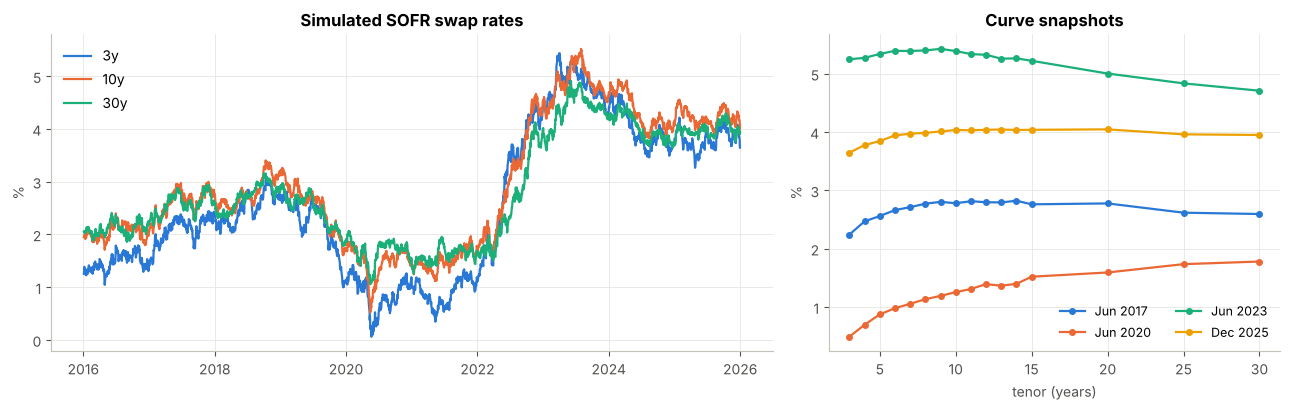

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for c, col in zip(["3y", "10y", "30y"], [C_BLUE, C_ORANGE, C_AQUA]):
    ax1.plot(rates.index, rates[c], color=col, label=c)
ax1.set_title("Simulated SOFR swap rates"); ax1.set_ylabel("%"); ax1.legend(loc="upper left")
ax1.xaxis.set_major_locator(mdates.YearLocator(2)); ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

snap_dates = ["2017-06-30", "2020-06-30", "2023-06-30", "2025-12-31"]
for d, col in zip(snap_dates, [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]):
    row = rates.loc[:d].iloc[-1]
    ax2.plot(TENORS, row.values, marker="o", ms=4, color=col, label=row.name.strftime("%b %Y"))
ax2.set_title("Curve snapshots"); ax2.set_xlabel("tenor (years)"); ax2.set_ylabel("%")
ax2.legend(loc="lower right", ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

## 2. PCA on daily changes: the three factors

First, a **full-sample** PCA, *for intuition only*. It uses the whole history, so it can't be used for trading (look-ahead). The backtest below re-estimates the PCA every day on a rolling window of **past** data.

In [4]:
d_bp = rates.diff().dropna() * 100            # daily changes in bp

def pca(changes, k=N_FACTORS):
    # Eigen-decomposition of the covariance of daily changes. Returns (loadings [tenor x k], explained ratio).
    cov = np.cov(changes, rowvar=False)
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    vecs = vecs[:, :k].copy()
    # Fix the arbitrary eigenvector sign so the factors read consistently:
    # PC1 positive on average (level up), PC2 positive at the long end (steepener),
    # PC3 positive in the belly (belly up vs wings).
    belly = np.zeros(changes.shape[1]); belly[3:9] = 1      # roughly 6y-11y
    refs = [np.ones(changes.shape[1]), np.linspace(-1, 1, changes.shape[1]), belly - belly.mean()]
    for j in range(min(k, 3)):
        if vecs[:, j] @ refs[j] < 0:
            vecs[:, j] *= -1
    return vecs, vals / vals.sum()

E_full, expl_full = pca(d_bp.values, k=len(COLS))
print("Explained variance (full sample):")
for j in range(5):
    print(f"  PC{j+1}: {expl_full[j]:6.1%}   cumulative {expl_full[:j+1].sum():6.1%}")

Explained variance (full sample):
  PC1:  88.8%   cumulative  88.8%
  PC2:   6.9%   cumulative  95.7%
  PC3:   2.4%   cumulative  98.1%
  PC4:   0.2%   cumulative  98.2%
  PC5:   0.2%   cumulative  98.4%


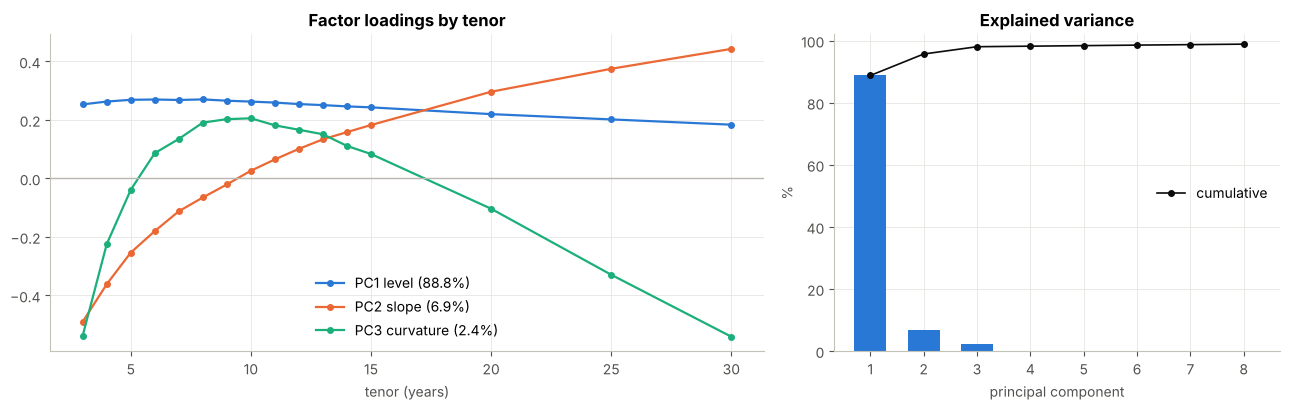

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
names = ["PC1 level", "PC2 slope", "PC3 curvature"]
for j, col in enumerate([C_BLUE, C_ORANGE, C_AQUA]):
    ax1.plot(TENORS, E_full[:, j], marker="o", ms=4, color=col,
             label=f"{names[j]} ({expl_full[j]:.1%})")
ax1.axhline(0, color=C_GREY, lw=1)
ax1.set_title("Factor loadings by tenor"); ax1.set_xlabel("tenor (years)"); ax1.legend()

ax2.bar(range(1, 9), expl_full[:8] * 100, color=C_BLUE, width=0.6)
ax2.plot(range(1, 9), np.cumsum(expl_full[:8]) * 100, color=C_INK, marker="o", ms=4, lw=1.2, label="cumulative")
ax2.set_title("Explained variance"); ax2.set_xlabel("principal component"); ax2.set_ylabel("%")
ax2.set_ylim(0, 102); ax2.legend(loc="center right")
plt.tight_layout(); plt.show()

## 3. Rolling out-of-sample fit, residuals and z-scores

For each day *t*:

1. Estimate the PCA loadings **E** (16 × 3) from daily changes over the previous `PCA_WINDOW` days (ending *t−1*).
2. Fit today's curve with the 3 factors: $\hat{x}_t = \mu + E E^\top (x_t - \mu)$, where $\mu$ is the average curve over the same window. This is "what the curve should look like given today's level, slope and curvature".
3. **Residual** $r_t = x_t - \hat{x}_t$ in bp. Positive means **cheap** (rate above the fit), negative means **rich**.
4. **Z-score** $z_t = (r_t - \bar{r}) / s_r$ using the previous `Z_WINDOW` days of residuals only.

Nothing here uses information from after day *t*.

In [6]:
X  = rates.values * 100                         # levels in bp
dX = np.vstack([np.full(len(COLS), np.nan), np.diff(X, axis=0)])
n, m = X.shape

resid    = np.full((n, m), np.nan)
loadings = np.full((n, m, N_FACTORS), np.nan)   # loadings available on day t (estimated to t-1)
expl_ts  = np.full((n, N_FACTORS), np.nan)

for t in range(PCA_WINDOW + 1, n):
    win = slice(t - PCA_WINDOW, t)              # days t-W .. t-1  (past only)
    E, ex = pca(dX[win])
    mu = X[win].mean(axis=0)
    fitted = mu + E @ (E.T @ (X[t] - mu))
    resid[t], loadings[t], expl_ts[t] = X[t] - fitted, E, ex[:N_FACTORS]

resid = pd.DataFrame(resid, index=rates.index, columns=COLS)
# z-score vs the residual's own trailing history (shifted so day t uses t-Z .. t-1)
r_mean = resid.rolling(Z_WINDOW, min_periods=Z_WINDOW).mean().shift(1)
r_std  = resid.rolling(Z_WINDOW, min_periods=Z_WINDOW).std().shift(1)
zscore = (resid - r_mean) / r_std

expl_ts = pd.DataFrame(expl_ts, index=rates.index, columns=["PC1", "PC2", "PC3"]).dropna()
print("Rolling explained variance (average over time):")
print(expl_ts.mean().map("{:.1%}".format).to_string(), f"\n  total: {expl_ts.sum(axis=1).mean():.1%}")
print(f"\nResidual std by tenor (bp):\n{resid.std().round(2).to_frame('bp').T.to_string()}")

Rolling explained variance (average over time):
PC1    88.7%
PC2     7.0%
PC3     2.3% 
  total: 98.0%

Residual std by tenor (bp):
     3y   4y   5y   6y   7y   8y   9y  10y  11y  12y  13y  14y  15y  20y  25y  30y
bp 1.51 1.90 2.15 1.91 1.64 2.26 1.84 2.03 1.70 1.88 1.97 2.19 2.31 2.27 1.46 1.38


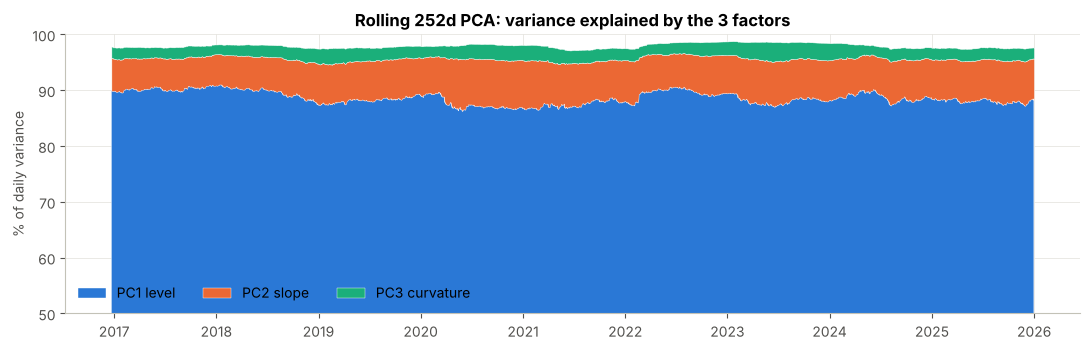

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.stackplot(expl_ts.index, (expl_ts * 100).T.values, colors=[C_BLUE, C_ORANGE, C_AQUA],
             labels=["PC1 level", "PC2 slope", "PC3 curvature"], edgecolor="white", linewidth=0.3)
ax.set_ylim(50, 100); ax.set_ylabel("% of daily variance")
ax.set_title(f"Rolling {PCA_WINDOW}d PCA: variance explained by the 3 factors")
ax.legend(loc="lower left", ncol=3)
plt.tight_layout(); plt.show()

### Rich / cheap today

This is the snapshot for Monday: the residual and z-score of each tenor on the latest date.

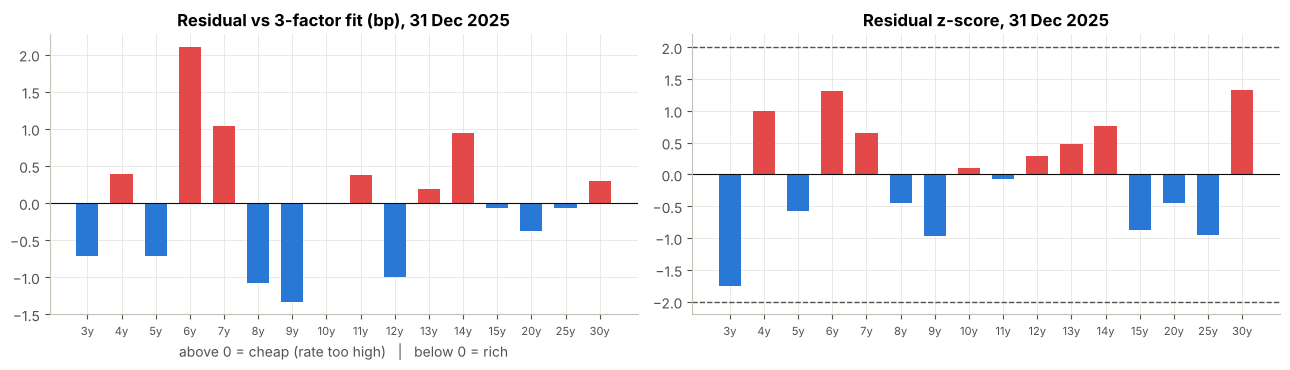

,rate %,residual bp,z,signal
3y,3.65,-0.71,-1.75,
4y,3.78,0.39,1.00,
5y,3.85,-0.71,-0.57,
6y,3.94,2.10,1.31,
7y,3.97,1.04,0.65,
8y,3.99,-1.08,-0.45,
9y,4.01,-1.33,-0.97,
10y,4.04,-0.01,0.11,
11y,4.03,0.38,-0.08,
12y,4.04,-1.00,0.29,


In [8]:
last = resid.dropna().index[-1]
snap = pd.DataFrame({"rate %": rates.loc[last], "residual bp": resid.loc[last], "z": zscore.loc[last]})
snap["signal"] = np.where(snap["z"] >= ENTRY_Z, "CHEAP: receive",
                 np.where(snap["z"] <= -ENTRY_Z, "RICH: pay", ""))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, colname, title in [(ax1, "residual bp", "Residual vs 3-factor fit (bp)"), (ax2, "z", "Residual z-score")]:
    v = snap[colname]
    ax.bar(COLS, v, color=np.where(v >= 0, C_RED, C_BLUE), width=0.65)
    ax.axhline(0, color=C_INK, lw=0.8)
    ax.set_title(f"{title}, {last:%d %b %Y}"); ax.tick_params(axis="x", labelsize=8)
for s in (ENTRY_Z, -ENTRY_Z):
    ax2.axhline(s, color=C_MUTED, lw=1, ls="--")
ax1.set_xlabel("above 0 = cheap (rate too high)   |   below 0 = rich")
plt.tight_layout(); plt.show()
snap.round(2)

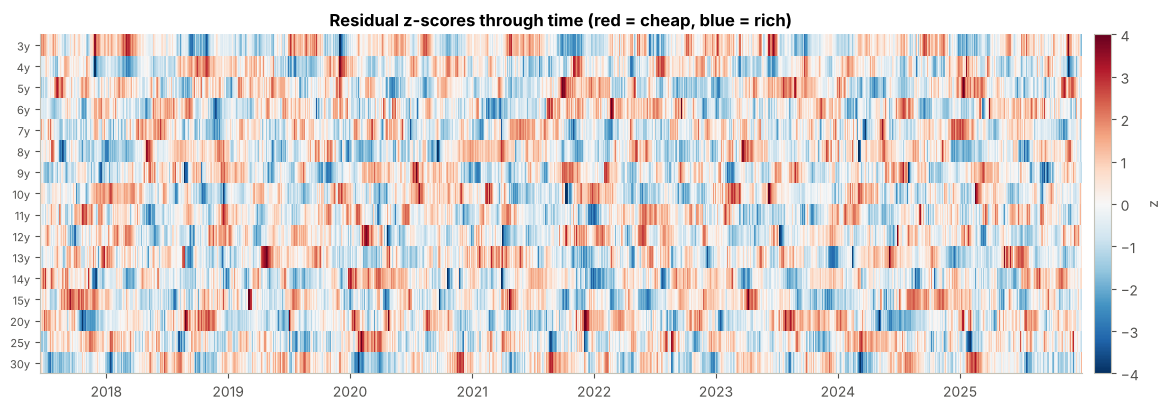

In [9]:
# Residual z-score heatmap across history (red = cheap, blue = rich)
zz = zscore.dropna(how="all")
fig, ax = plt.subplots(figsize=(13, 4.2))
im = ax.imshow(zz.T.values, aspect="auto", cmap="RdBu_r", vmin=-4, vmax=4, interpolation="nearest",
               extent=[mdates.date2num(zz.index[0]), mdates.date2num(zz.index[-1]), m - 0.5, -0.5])
ax.set_yticks(range(m)); ax.set_yticklabels(COLS, fontsize=8); ax.grid(False)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Residual z-scores through time (red = cheap, blue = rich)")
fig.colorbar(im, ax=ax, pad=0.01, label="z")
plt.tight_layout(); plt.show()

## 4. Trading rule and backtest

**Construction.** When a tenor's z-score hits ±`ENTRY_Z`, trade a **butterfly**: the signal tenor is the belly and its neighbours are the wings. The wing weights are solved so the trade has **zero exposure to PC1 (level) and PC2 (slope)**, using the loadings available that day. Weights are in DV01 terms (belly = 1).

- z ≥ +2 (cheap): **receive** the belly, pay the wings.
- z ≤ −2 (rich): **pay** the belly, receive the wings.

**Exit** when z crosses back through 0, or on a stop (|z| ≥ `STOP_Z` in the wrong direction), or after `MAX_HOLD` days.

**Execution.** Signal at close *t*, trade at close *t+1* (`EXEC_LAG`). P&L is in **bp per 1 unit of belly DV01**. **Costs** are the full bid-offer on every leg, scaled by its weight (half the spread in, half out). The end tenors (3y, 30y) have no neighbour on one side, so they aren't traded.

In [10]:
def fly_weights(E, i):
    # DV01 weights for belly i with wings i-1, i+1, neutral to PC1 & PC2. Returns {idx: weight}.
    a, b = i - 1, i + 1
    A = np.array([[E[a, 0], E[b, 0]], [E[a, 1], E[b, 1]]])
    wa, wb = np.linalg.solve(A, -np.array([E[i, 0], E[i, 1]]))
    return {a: wa, i: 1.0, b: wb}

def backtest(entry_z=ENTRY_Z, exit_z=EXIT_Z, stop_z=STOP_Z, max_hold=MAX_HOLD,
             lag=EXEC_LAG, cost_mult=1.0, tenors=None):
    Z = zscore.values
    bo = np.array([BID_OFFER[c] for c in COLS]) * cost_mult
    trades = []
    for i in range(1, m - 1):                          # interior tenors only
        if tenors is not None and COLS[i] not in tenors:
            continue
        t = 0
        while t < n - lag:
            z = Z[t, i]
            if np.isnan(z) or abs(z) < entry_z:
                t += 1; continue
            side = -1 if z > 0 else +1                 # -1 = receive belly (cheap), +1 = pay belly (rich)
            te = t + lag                               # execution day
            w = fly_weights(loadings[t], i)
            fly = lambda d: sum(wt * X[d, j] for j, wt in w.items())
            # find exit signal
            reason, tx_sig = "end of data", None
            for s in range(t + 1, n - lag):
                zs = Z[s, i]
                if np.isnan(zs):
                    continue
                if (z > 0 and zs <= exit_z) or (z < 0 and zs >= -exit_z):
                    reason, tx_sig = "reverted", s; break
                if abs(zs) >= stop_z and np.sign(zs) == np.sign(z):
                    reason, tx_sig = "stop", s; break
                if s - t >= max_hold:
                    reason, tx_sig = "max hold", s; break
            tx = (tx_sig + lag) if tx_sig is not None else n - 1
            gross = side * (fly(tx) - fly(te))
            cost = sum(abs(wt) * bo[j] for j, wt in w.items())
            trades.append(dict(tenor=COLS[i], side="receive" if side < 0 else "pay",
                               signal_date=rates.index[t], entry_date=rates.index[te],
                               exit_date=rates.index[tx], entry_z=z, hold_days=tx - te,
                               gross_bp=gross, cost_bp=cost, net_bp=gross - cost, exit=reason,
                               w_wings=round(w[i-1], 2), w_wing_hi=round(w[i+1], 2)))
            t = tx + 1                                 # one position per tenor at a time
    return pd.DataFrame(trades)

def summarize(tr, by=None):
    f = lambda g: pd.Series({
        "trades": len(g), "hit rate (net)": (g.net_bp > 0).mean(), "avg hold (d)": g.hold_days.mean(),
        "avg gross bp": g.gross_bp.mean(), "avg cost bp": g.cost_bp.mean(),
        "avg net bp": g.net_bp.mean(), "total net bp": g.net_bp.sum(),
        "worst bp": g.net_bp.min(), "% reverted": (g.exit == "reverted").mean()})
    return tr.groupby(tr[by].values).apply(f).rename_axis(by) if by else f(tr).to_frame("all").T

trades = backtest()
print(f"{len(trades)} trades, {trades.entry_date.min():%Y-%m-%d} to {trades.exit_date.max():%Y-%m-%d}")
summarize(trades)

503 trades, 2017-06-19 to 2025-12-29


,trades,hit rate (net),avg hold (d),avg gross bp,avg cost bp,avg net bp,total net bp,worst bp,% reverted
all,503.00,0.72,21.37,2.06,0.90,1.16,581.13,-12.51,0.87


In [11]:
fmt = {"trades": "{:.0f}", "hit rate (net)": "{:.0%}", "% reverted": "{:.0%}"}
by_tenor = summarize(trades, by="tenor").reindex([c for c in COLS if c in trades.tenor.unique()])
by_tenor["liquid"] = by_tenor.index.isin(LIQUID)
by_tenor.style.format({**{c: "{:.2f}" for c in by_tenor.columns if c not in fmt and c != "liquid"}, **fmt})

,trades,hit rate (net),avg hold (d),avg gross bp,avg cost bp,avg net bp,total net bp,worst bp,% reverted,liquid
tenor,,,,,,,,,,
4y,35,74%,21.86,2.01,0.90,1.11,38.93,-5.10,83%,False
5y,34,65%,25.82,1.47,0.91,0.56,19.11,-5.99,82%,True
6y,40,70%,18.12,1.78,0.90,0.88,35.29,-8.45,90%,False
7y,42,81%,16.57,2.14,0.90,1.25,52.39,-3.68,98%,True
8y,37,65%,22.54,2.24,1.06,1.18,43.64,-9.27,84%,False
9y,30,73%,24.93,2.27,1.06,1.21,36.21,-4.36,93%,False
10y,34,59%,23.50,1.41,0.90,0.51,17.23,-12.51,79%,True
11y,38,79%,21.21,2.18,0.90,1.27,48.37,-2.17,97%,False
12y,34,82%,20.38,3.36,0.90,2.46,83.76,-2.46,91%,True


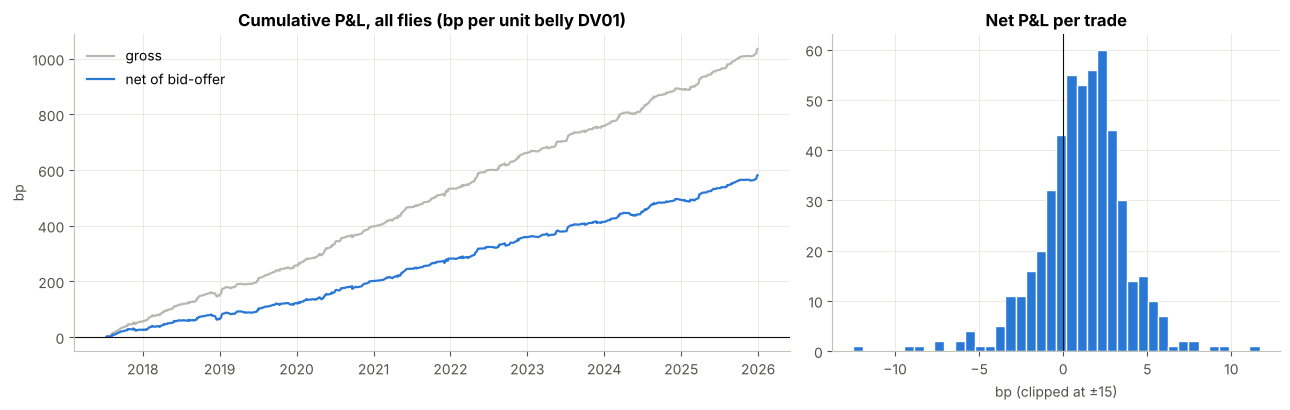

          trades  hit rate (net)  avg hold (d)  avg gross bp  avg cost bp  avg net bp  total net bp  worst bp  % reverted
exit                                                                                                                     
max hold   31.00            0.06         60.00         -1.50         0.90       -2.40        -74.41     -6.14        0.00
reverted  440.00            0.81         19.71          2.61         0.90        1.71        752.38     -3.68        1.00
stop       32.00            0.19          6.84         -2.15         0.88       -3.03        -96.83    -12.51        0.00


In [12]:
tr = trades.sort_values("exit_date")
cum_g, cum_n = tr.set_index("exit_date").gross_bp.cumsum(), tr.set_index("exit_date").net_bp.cumsum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(cum_g.index, cum_g.values, color=C_GREY, label="gross")
ax1.plot(cum_n.index, cum_n.values, color=C_BLUE, label="net of bid-offer")
ax1.axhline(0, color=C_INK, lw=0.8)
ax1.set_title("Cumulative P&L, all flies (bp per unit belly DV01)"); ax1.set_ylabel("bp"); ax1.legend()

ax2.hist(trades.net_bp.clip(-15, 15), bins=40, color=C_BLUE, edgecolor="white")
ax2.axvline(0, color=C_INK, lw=0.8)
ax2.set_title("Net P&L per trade"); ax2.set_xlabel("bp (clipped at ±15)")
plt.tight_layout(); plt.show()

print(summarize(trades, by="exit").round(2).to_string())

### Liquid vs off-the-run points

Off-the-run tenors (4y, 6y, 8y, 9y, 11y, 13y, 14y) pay double the bid-offer in this setup. Since a typical dislocation is only 1–3bp, costs matter a lot.

In [13]:
trades["bucket"] = np.where(trades.tenor.isin(LIQUID), "liquid", "off-the-run")
summarize(trades, by="bucket").style.format({"trades": "{:.0f}", "hit rate (net)": "{:.0%}",
    "% reverted": "{:.0%}", **{c: "{:.2f}" for c in ["avg hold (d)", "avg gross bp", "avg cost bp",
    "avg net bp", "total net bp", "worst bp"]}})

,trades,hit rate (net),avg hold (d),avg gross bp,avg cost bp,avg net bp,total net bp,worst bp,% reverted
bucket,,,,,,,,,
liquid,248,72%,21.47,1.92,0.81,1.11,274.82,-12.51,86%
off-the-run,255,73%,21.28,2.19,0.99,1.20,306.32,-9.27,89%


### Sensitivity: entry threshold × cost level

A credible result shouldn't depend on one magic threshold. The table shows average **net** bp per trade (and trade counts).

In [14]:
rows = []
for ez in [1.5, 2.0, 2.5, 3.0]:
    for cm in [0.0, 1.0, 2.0]:
        tr_ = backtest(entry_z=ez, cost_mult=cm)
        rows.append(dict(entry_z=ez, cost=f"{cm:.0f}x bid-offer", avg_net=tr_.net_bp.mean(),
                         trades=len(tr_), hit=(tr_.net_bp > 0).mean()))
sens = pd.DataFrame(rows)
print("Average net bp per trade")
print(sens.pivot(index="entry_z", columns="cost", values="avg_net").round(2).to_string())
print("\nHit rate")
print(sens.pivot(index="entry_z", columns="cost", values="hit").map("{:.0%}".format).to_string())
print("\nNumber of trades")
print(sens.pivot(index="entry_z", columns="cost", values="trades").iloc[:, 0].to_string())

Average net bp per trade
cost     0x bid-offer  1x bid-offer  2x bid-offer
entry_z                                          
1.50             1.80          0.91          0.01
2.00             2.06          1.16          0.25
2.50             2.48          1.58          0.68
3.00             2.79          1.89          0.99

Hit rate
cost    0x bid-offer 1x bid-offer 2x bid-offer
entry_z                                       
1.50             84%          71%          51%
2.00             83%          72%          57%
2.50             86%          75%          66%
3.00             84%          73%          65%

Number of trades
entry_z
1.50    809
2.00    503
2.50    301
3.00    152


## 5. Caveat: structural cheapness (the 20y)

From mid-2023 the simulated 20y cheapens by about 6bp **and stays there**. That mirrors a real persistent driver (supply, pension or LDI hedging flow, a benchmark change). The residual goes to +2σ and the model says "receive", but the point never comes back. Those trades lose and exit via stop or max-hold. The 'cheapness' only fades once the rolling PCA window (~1y) has absorbed the new level, i.e. the model adapts *after* the money is lost.

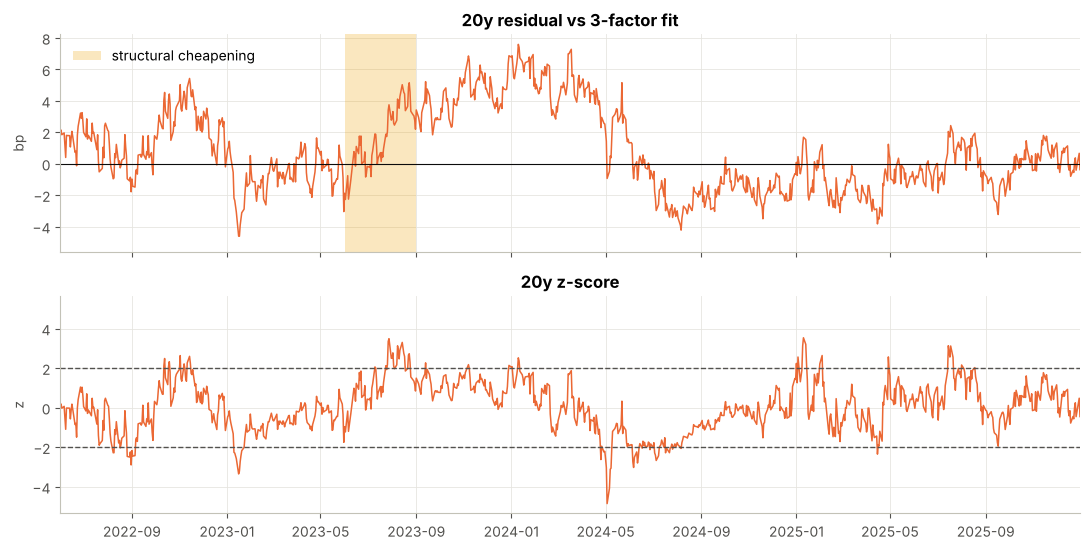

,side,entry_date,exit_date,entry_z,hold_days,net_bp,exit
462,receive,2023-07-11,2023-10-03,2.06,60,-5.48,max hold
463,receive,2023-11-07,2023-12-18,2.08,29,0.65,reverted
464,receive,2024-01-01,2024-02-06,2.14,26,0.93,reverted


In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
ax1.plot(resid.index, resid["20y"], color=C_ORANGE, lw=1.1)
ax1.axvspan(pd.Timestamp("2023-06-01"), pd.Timestamp("2023-09-01"), color=C_YELLOW, alpha=0.25, lw=0,
            label="structural cheapening")
ax1.axhline(0, color=C_INK, lw=0.8); ax1.set_ylabel("bp"); ax1.legend(loc="upper left")
ax1.set_title("20y residual vs 3-factor fit")
ax2.plot(zscore.index, zscore["20y"], color=C_ORANGE, lw=1.1)
for s in (ENTRY_Z, -ENTRY_Z):
    ax2.axhline(s, color=C_MUTED, lw=1, ls="--")
ax2.set_ylabel("z"); ax2.set_title("20y z-score")
ax2.set_xlim(pd.Timestamp("2022-06-01"), rates.index[-1])
plt.tight_layout(); plt.show()

t20 = trades[(trades.tenor == "20y") & (trades.entry_date >= "2023-05-01") & (trades.entry_date <= "2024-03-31")]
t20[["side", "entry_date", "exit_date", "entry_z", "hold_days", "net_bp", "exit"]].round({"entry_z": 2, "net_bp": 2})

## 6. Takeaways for the write-up

- **Three factors explain the vast majority of daily curve moves** (see the explained-variance table). The residuals are small, typically 1–2bp.
- The PCA is **re-estimated daily on a rolling past-only window**, z-scores use only past residuals, and trades execute the day *after* the signal. There's no look-ahead.
- Trades are **butterflies hedged to level and slope**, so P&L comes from the residual, not from a directional or curve view.
- **Report net P&L.** Compare gross vs net, and liquid vs off-the-run. Bid-offer takes a large share of a 1–2bp edge, especially in off-the-run points.
- **Caveat:** some cheap points stay cheap for structural reasons (supply, hedging flows). The signal works best in liquid benchmarks and fails around regime shifts (see the 20y). In practice, pair the signal with a fundamental check of *why* a point is dislocated.

**Possible extensions:** hedge PC3 too (4-leg trades), DV01-weighted P&L in $ for a notional, a regime filter (pause when rolling explained variance drops), carry/roll-down on each fly, and of course replacing Section 1 with Bloomberg data (`USOSFR3 Curncy … USOSFR30 Curncy`).

*Note: all results above come from **simulated** data, so they illustrate the methodology and are not evidence of real-world profitability.*